# Exercise 1 — Predicting an unknown endpoint

**Part II · Practical work** · Group 9 – Herzog, Redlich, Kriewald

Predict the unknown endpoint $L$ from ten observations. Train four networks in **(a)**, compare their errors in **(b)**, and evaluate fixed endpoints in **(c)**.

Run the cells from top to bottom. The network implementation is adapted from `SLT_Neural_Networks_Epsilon_Loss.ipynb`. Changes to the template and optional additions are noted below.

## Shared setup

Prepare the libraries, shared settings and reusable functions. Constants specific to **(a)**, **(b)** and **(c)** stay in their respective sections.

### Libraries and types

Import the numerical and plotting libraries. `FloatArray` specifies floating-point entries, `HiddenLayers` describes the widths of the hidden layers.

In [19]:
import time
from typing import TypeAlias, cast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.typing import NDArray

FloatArray: TypeAlias = NDArray[np.float64]
HiddenLayers: TypeAlias = tuple[int, ...]

### Shared constants

Use $N=10$ observations per input vector. `DATA_SEED` is the reproducible starting seed taken from the course notebook.

In [20]:
N: int = 10  # Observations per input vector.
DATA_SEED: int = 7  # Base seed from the course notebook.

### Plot appearance

Set font size, figure resolution and grid styling. These choices affect appearance only, not data, training or results.

In [21]:
# matplotlib settings (mainly taken from the example notebooks)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})

### Reproducible sampling

Initialize the base seed sequence. Each task derives its own streams. A full top-to-bottom run reproduces the data. Re-running a stream-setting cell creates a new stream.

In [22]:
seed_sequence: np.random.SeedSequence = np.random.SeedSequence(DATA_SEED)

### Reusable functions

Define sampling, MSE and the three comparison rules $h_1,h_2,h_3$. These helpers are reused below.

In [23]:
def sample_examples(
    m: int, random_generator: np.random.Generator
) -> tuple[FloatArray, FloatArray]:
    """Generate examples for training or testing.

    :param m: Number of complete examples, each containing N observations.
    :param random_generator: random generator for endpoints and observations.
    :return: Sorted inputs of shape (m, N) and endpoint labels of shape (m,).
        Each endpoint is drawn uniformly from [1, 5]. Conditional on that
        endpoint, the N observations are independent uniform draws from [0, L].
    """
    labels: FloatArray = random_generator.uniform(1.0, 5.0, m)
    uniform_samples: FloatArray = random_generator.uniform(size=(m, N))
    endpoints_column: FloatArray = labels.reshape(m, 1)
    inputs: FloatArray = uniform_samples * endpoints_column
    return np.sort(inputs, axis=1), labels


def mse(y: FloatArray, predictions: FloatArray) -> float:
    """Compute the empirical mean squared prediction error.

    :param y: True endpoint labels, shape (m,).
    :param predictions: Predicted endpoints, shape (m,), matching y.
    :return: Average squared prediction error.
    :raises ValueError: If inputs are not one-dimensional, have different
        shapes, or contain no examples.
    """
    if y.ndim != 1 or y.shape != predictions.shape or y.size == 0:
        raise ValueError('Expected non-empty 1D arrays of the same shape.')
    return float(np.mean((y - predictions) ** 2))


def baselines(X: FloatArray) -> dict[str, FloatArray]:
    """Predict endpoints using the three rules specified in Task I.1.

    :param X: Observations of shape (m, N), one example per row;
        sorting is not required. N is the global input size.
    :return: Predictions for h1, h2 and h3, each of shape
        (m,): twice the row mean, the row maximum, and (N + 1) / N
        times the row maximum, respectively.
    """
    maximum: FloatArray = X.max(axis=1)
    return {'h1': 2 * X.mean(axis=1), 'h2': maximum,
            'h3': ((N + 1) / N) * maximum}

## II(a) — Train the four networks

Generate each example as specified in **Task I.2**:

1. Draw $L\sim\mathrm{Uniform}[1,5]$.
2. Given $L$, draw $N=10$ independent observations from $\mathrm{Uniform}[0,L]$.

**Input:** the sorted observations. **Target:** the endpoint $L$.

Use the same $m=10{,}000$ training examples for all four prescribed architectures.

### II(a) — Training settings

Set the required training size and four architectures. Epochs, learning rate and initialization seeds follow the course network notebook

**Addition:** `MAX_WORKERS` controls the added parallel execution.

In [24]:
N_TRAIN: int = 10_000
ARCHITECTURES: list[HiddenLayers] = [(16,), (64,), (32, 32), (64, 64, 32)]

# Common training settings from the course notebook.
EPOCHS: int = 4000
LEARNING_RATE: float = 0.003
INIT_SEEDS: list[int] = [11, 22, 33]

# Workers for parallel training. The course notebook uses 1, or 3
MAX_WORKERS: int = 3

training_stream: np.random.SeedSequence = seed_sequence.spawn(1)[0]

### II(a).1 — Generate training examples

Draw the training data and preview three examples. Each row of `X_train` contains $N=10$ sorted values. The matching entry in `y_train` is its endpoint $L$.

**Shapes:** `X_train`: $(m,N)$ · `y_train`: $(m,)$.

In [25]:
X_train: FloatArray
y_train: FloatArray
X_train, y_train = sample_examples(N_TRAIN, np.random.default_rng(training_stream))

print('Training:', X_train.shape, '| Label range:', y_train.min(), y_train.max())
display(pd.DataFrame(X_train[:3], columns=[f'u{i+1}' for i in range(N)])
        .assign(L=y_train[:3]).round(3))

Training: (10000, 10) | Label range: 1.000001149171522 4.999787752448674


,u1,u2,u3,u4,u5,u6,u7,u8,u9,u10,L
0,0.391,0.881,0.958,1.884,1.983,2.077,2.711,2.874,3.407,4.131,4.191
1,0.114,0.123,0.166,0.182,0.198,0.314,0.492,1.016,1.147,1.190,1.212
2,0.001,0.245,0.499,1.400,1.662,1.703,2.429,2.875,2.897,2.957,3.365


### II(a).2 — Define the network

Define tanh hidden layers and a linear output predicting $L$. This cell creates the network class. It does not train a model.

**Source and adaptation:** Adapted from course notebook. MSE replaces the template's ε-insensitive loss, following Part I's error criterion.

In [26]:
# NumPy network and Adam follow the course template; gradient adapted for MSE.
class Network:
    def __init__(self, hidden: HiddenLayers, seed: int) -> None:
        """Create the layers with random initial weights and zero biases."""
        rng: np.random.Generator = np.random.default_rng(seed)
        sizes: tuple[int, ...] = (N,) + tuple(hidden) + (1,)
        self.W: list[FloatArray] = [rng.normal(size=(a, b)) * np.sqrt(2 / (a + b))
                  for a, b in zip(sizes[:-1], sizes[1:])]
        self.b: list[FloatArray] = [np.zeros((1, b)) for b in sizes[1:]]

    def forward(self, X: FloatArray) -> list[FloatArray]:
        """Pass inputs through the network and return inputs and all layer outputs."""
        activations: list[FloatArray] = [X]
        for j, (W, b) in enumerate(zip(self.W, self.b)):
            z = activations[-1] @ W + b
            activations.append(np.tanh(z) if j < len(self.W) - 1 else z)
        return activations

    def predict(self, X: FloatArray) -> FloatArray:
        """Return one predicted endpoint L per input vector, shape (m,)."""
        return self.forward(X)[-1].ravel()

    def gradients(self, X: FloatArray, y: FloatArray) -> list[FloatArray]:
        """Backpropagate the MSE to compute gradients for all weights and biases."""
        acts: list[FloatArray] = self.forward(X)
        # Adaptation of the course template: derivative of MSE, not ε-loss.
        delta: FloatArray = 2 * (acts[-1] - np.asarray(y).reshape(-1, 1)) / len(X)
        gW: list[FloatArray | None] = [None] * len(self.W)
        gb: list[FloatArray | None] = [None] * len(self.b)
        for j in reversed(range(len(self.W))):
            gW[j] = acts[j].T @ delta
            gb[j] = delta.sum(axis=0, keepdims=True)
            if j > 0:
                delta = (delta @ self.W[j].T) * (1 - acts[j] ** 2)
        # The loop fills every placeholder before returning.
        return cast(list[FloatArray], gW + gb)

    def copy_parameters(self) -> list[FloatArray]:
        """Copy the current weights and biases to save a training checkpoint."""
        return [p.copy() for p in self.W + self.b]

    def set_parameters(self, values: list[FloatArray]) -> None:
        """Restore the weights and biases from a saved parameter list."""
        for param, value in zip(self.W + self.b, values):
            param[:] = value

### II(a).3 — Define the training procedure

Define full-batch Adam training with the configured epoch budget. Each run saves and restores its lowest-training-MSE checkpoint, following the course template with the MSE adaptation above. No training is executed yet.

In [27]:
def architecture_name(hidden: HiddenLayers) -> str:
    """Build a readable architecture label including the input and output layers."""
    return ' → '.join(map(str, (N,) + tuple(hidden) + (1,)))

TrainingResult: TypeAlias = tuple[Network, float, int, FloatArray]

def train(hidden: HiddenLayers, seed: int) -> TrainingResult:
    """Train with full-batch Adam and return the best model, MSE, epoch and history."""
    net: Network = Network(hidden, seed)
    params: list[FloatArray] = net.W + net.b
    moment: list[FloatArray] = [np.zeros_like(p) for p in params]
    variance: list[FloatArray] = [np.zeros_like(p) for p in params]
    best_loss: float = np.inf
    best_parameters: list[FloatArray] | None = None
    best_epoch: int = 0
    history: list[tuple[int, float]] = []
    for epoch in range(1, EPOCHS + 1):
        gradients = net.gradients(X_train, y_train)
        for j, (param, grad) in enumerate(zip(params, gradients)):
            moment[j] = 0.9 * moment[j] + 0.1 * grad
            variance[j] = 0.999 * variance[j] + 0.001 * grad ** 2
            param -= LEARNING_RATE * (moment[j] / (1 - 0.9 ** epoch)) / (
                np.sqrt(variance[j] / (1 - 0.999 ** epoch)) + 1e-8)
        # Retain the best TRAINING iterate. Validation never enters this choice.
        loss = mse(y_train, net.predict(X_train))
        if loss < best_loss:
            best_loss, best_parameters, best_epoch = loss, net.copy_parameters(), epoch
        if epoch == 1 or epoch % 100 == 0 or epoch == EPOCHS:
            history.append((epoch, loss))
    # Positive EPOCHS and finite losses ensure a checkpoint was saved.
    net.set_parameters(cast(list[FloatArray], best_parameters))
    return net, best_loss, best_epoch, np.asarray(history)

### II(a).4 — Train and retain one network per architecture

Train each architecture with three initialization seeds (**12 runs**). Retain the lowest-training-MSE run per architecture. Test data are not used for selection.

**Implementation addition:** Unlike the course notebook, `ThreadPoolExecutor` runs up to `MAX_WORKERS` independent fits in parallel.

In [28]:
from concurrent.futures import ThreadPoolExecutor, as_completed

# Parallelize independent runs only; batch size and epoch count are unchanged.
models: dict[str, Network] = {}
histories: dict[str, FloatArray] = {}
runs: list[dict[str, str | int | float]] = []
selected_runs: dict[str, dict[str, int]] = {}
trials: dict[tuple[HiddenLayers, int], TrainingResult] = {}
started: float = time.perf_counter()
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    jobs = {pool.submit(train, hidden, seed): (hidden, seed)
            for hidden in reversed(ARCHITECTURES) for seed in INIT_SEEDS}
    for job in as_completed(jobs):
        hidden, seed = jobs[job]
        net, loss, best_epoch, history = job.result()
        trials[(hidden, seed)] = (net, loss, best_epoch, history)
        print(f'{architecture_name(hidden)}, Seed {seed}: Train-MSE {loss:.6f}', flush=True)
for hidden in ARCHITECTURES:
    name = architecture_name(hidden)
    for seed in INIT_SEEDS:
        net, loss, best_epoch, history = trials[(hidden, seed)]
        runs.append({'Model': name, 'Seed': seed, 'Train-MSE': loss,
                     'Best training epoch': best_epoch})
    seed = min(INIT_SEEDS, key=lambda s: trials[(hidden, s)][1])
    # Select by training MSE only; index 1 is the loss in TrainingResult.
    net, loss, best_epoch, history = trials[(hidden, seed)]
    models[name], histories[name] = net, history
    selected_runs[name] = {'Seed': seed, 'Epoch': best_epoch}
print(f'Training time: {(time.perf_counter() - started) / 60:.1f} min')
display(pd.DataFrame(runs).round(6))

10 → 64 → 64 → 32 → 1, Seed 33: Train-MSE 0.081209
10 → 64 → 64 → 32 → 1, Seed 22: Train-MSE 0.081340
10 → 64 → 64 → 32 → 1, Seed 11: Train-MSE 0.081264
10 → 32 → 32 → 1, Seed 11: Train-MSE 0.081592
10 → 32 → 32 → 1, Seed 22: Train-MSE 0.081487
10 → 32 → 32 → 1, Seed 33: Train-MSE 0.081573
10 → 64 → 1, Seed 11: Train-MSE 0.081731
10 → 16 → 1, Seed 11: Train-MSE 0.081995
10 → 64 → 1, Seed 22: Train-MSE 0.081637
10 → 64 → 1, Seed 33: Train-MSE 0.081791
10 → 16 → 1, Seed 22: Train-MSE 0.081993
10 → 16 → 1, Seed 33: Train-MSE 0.081961
Training time: 6.6 min


,Model,Seed,Train-MSE,Best training epoch
0,10 → 16 → 1,11,0.081995,4000
1,10 → 16 → 1,22,0.081993,4000
2,10 → 16 → 1,33,0.081961,4000
3,10 → 64 → 1,11,0.081731,4000
4,10 → 64 → 1,22,0.081637,4000
5,10 → 64 → 1,33,0.081791,4000
6,10 → 32 → 32 → 1,11,0.081592,4000
7,10 → 32 → 32 → 1,22,0.081487,4000
8,10 → 32 → 32 → 1,33,0.081573,4000
9,10 → 64 → 64 → 32 → 1,11,0.081264,4000


## II(b) — Compare training and test errors

Evaluate the four fitted networks and $h_1,h_2,h_3$ on shared training and test data. Present one table and one plot. Do not retrain the networks.

**Theory from Part I, Task 2(b):** for $N=10$ and $L\sim\mathrm{Uniform}[1,5]$,
$$R(h_1)=\tfrac{31}{90}\approx0.3444,\qquad R(h_2)=\tfrac{31}{198}\approx0.1566,\qquad R(h_3)=\tfrac{31}{360}\approx0.0861.$$

### II(b) — Test settings and theoretical risks

Set the required 20,000 test examples and the population risks from Part I, Task 2(b).

In [29]:
test_stream: np.random.SeedSequence = seed_sequence.spawn(1)[0]

N_TEST: int = 20_000

# Population risks from Part I, Task 2(b), for N = 10 and L ~ Uniform[1, 5].
theory: dict[str, float | None] = {
    'h1': 31 / 90,
    'h2': 31 / 198,
    'h3': 31 / 360,
}

### II(b).1 — Generate independent test examples

Draw 20,000 new examples from Task I.2 using the test seed. All seven rules receive this same test set, which was not used for fitting or initialization selection.

In [30]:
X_test: FloatArray
y_test: FloatArray
X_test, y_test = sample_examples(N_TEST, np.random.default_rng(test_stream))

### II(b).2 — Table of prediction errors

Compute training MSE and test MSE for all seven rules. The column `Theory` contains the population risks from I.2(b) for h₁, h₂ and h₃. `NaN` indicates that no theoretical value is provided. The fitted networks remain unchanged.

**Optional addition:** Test standard errors quantify sampling uncertainty for fixed models, assuming independent examples and finite loss variance. They do not cover variability from retraining.

In [31]:
train_predictions: dict[str, FloatArray] = {name: net.predict(X_train) for name, net in models.items()}
test_predictions: dict[str, FloatArray] = {name: net.predict(X_test) for name, net in models.items()}
train_predictions.update(baselines(X_train))
test_predictions.update(baselines(X_test))
rows: list[dict[str, str | float | np.float64]] = []
for name in train_predictions:
    losses = (test_predictions[name] - y_test) ** 2
    theory_value = theory.get(name)
    rows.append({'Model': name, 'Train-MSE': mse(y_train, train_predictions[name]),
                 'Test-MSE': losses.mean(), 'Test-SE': losses.std(ddof=1) / np.sqrt(N_TEST),
                 'Theory': theory_value if theory_value is not None else np.nan})
comparison: pd.DataFrame = pd.DataFrame(rows).set_index('Model')
display(comparison.round(6))

,Train-MSE,Test-MSE,Test-SE,Theory
Model,,,,
10 → 16 → 1,0.081961,0.079010,0.001578,NaN
10 → 64 → 1,0.081637,0.078817,0.001571,NaN
10 → 32 → 32 → 1,0.081487,0.078654,0.001570,NaN
10 → 64 → 64 → 32 → 1,0.081209,0.078639,0.001569,NaN
h1,0.355208,0.344141,0.004358,0.344444
h2,0.164297,0.158839,0.002627,0.156566
h3,0.092485,0.088228,0.001714,0.086111


### II(b).3 — Plot training and test MSE

Show training and test MSE side by side. Dashed black lines mark the three theoretical risks.

**Optional addition:** Error bars show ±2 test standard errors, not guaranteed confidence bounds.

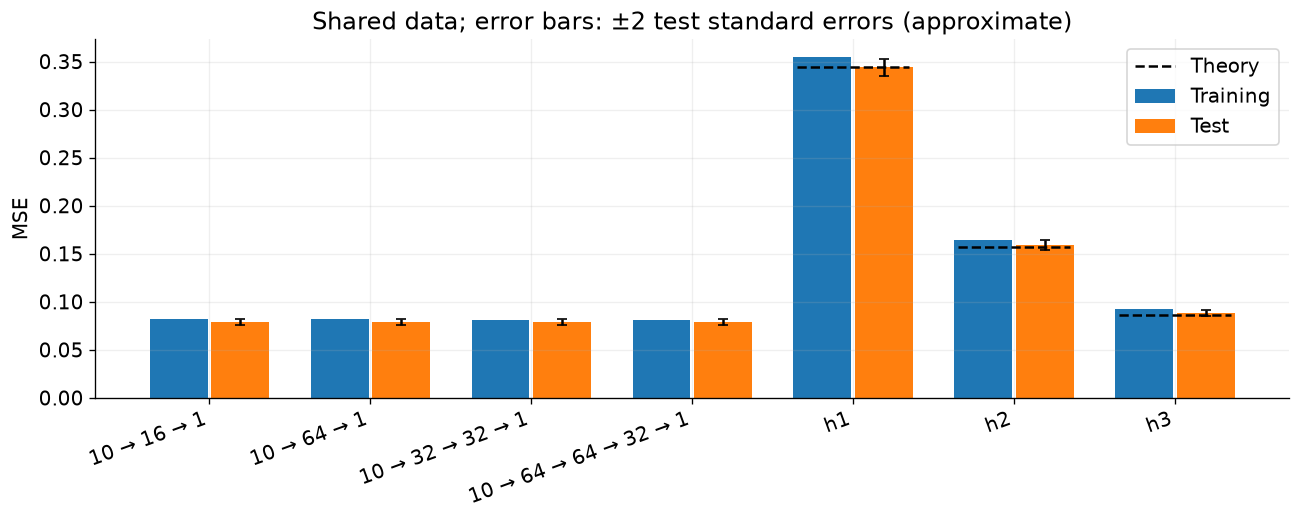

In [32]:
fig, ax = plt.subplots(figsize=(11, 4.5))
positions = np.arange(len(comparison))
ax.bar(positions - 0.19, comparison['Train-MSE'], width=0.36, label='Training')
ax.bar(positions + 0.19, comparison['Test-MSE'], width=0.36, label='Test',
       yerr=2 * comparison['Test-SE'], capsize=3)
theory_label: str = 'Theory'
for i, name in enumerate(comparison.index):
    theory_value = theory.get(name)
    if theory_value is not None:
        ax.plot([i - 0.35, i + 0.35], [theory_value] * 2, color='black',
                linestyle='--', label=theory_label)
        theory_label = '_nolegend_'
ax.set_xticks(positions, comparison.index, rotation=20, ha='right')
ax.set(ylabel='MSE', title='Shared data; error bars: ±2 test standard errors (approximate)')
ax.legend()
plt.tight_layout()
plt.show()

### II(b).4 — Notes on reading the comparison

The test errors of $h_1,h_2,h_3$ agree very well with theory and reproduce the predicted ranking, while the four networks achieve similar errors below those of $h_3$. Lower test than training errors also occur for the untrained rules and are consistent with sampling variation.

## II(c) — Evaluate fixed endpoints

For each $L\in\{0.5,1,2,3,4,5,6,8\}$, evaluate all seven rules on 5,000 fresh input vectors. Keep the trained networks unchanged and plot empirical MSE against $L$.

### II(c) — Fixed-endpoint settings

Set the prescribed endpoints and 5,000 examples per endpoint. Create a separate random stream for each endpoint.

In [33]:
N_FIXED: int = 5_000
L_VALUES: FloatArray = np.array([0.5, 1, 2, 3, 4, 5, 6, 8])
fixed_streams: list[np.random.SeedSequence] = seed_sequence.spawn(len(L_VALUES))

### II(c).1 — Define sampling at a fixed $L$

Define a sampler that draws $N=10$ independent observations from $[0,L]$ and sorts them. Unlike Task I.2, $L$ stays fixed within each experiment, so all examples in that group have the same label.

In [34]:
def sample_fixed_endpoint(
    m: int, random_generator: np.random.Generator, fixed_L: float
) -> tuple[FloatArray, FloatArray]:
    """Generate fresh observation vectors for a fixed endpoint in Task II(c).

    :param m: Number of complete examples, each containing N observations.
    :param random_generator: Random generator for the observations.
    :param fixed_L: Positive endpoint shared by all examples.
    :return: Sorted inputs of shape (m, N) and labels of shape (m,),
        all equal to fixed_L. Each observation is drawn uniformly from [0, fixed_L].
    """
    labels: FloatArray = np.full(m, fixed_L, dtype=float)
    inputs: FloatArray = random_generator.uniform(size=(m, N)) * labels[:, None]
    return np.sort(inputs, axis=1), labels

### II(c).2 — Compute errors at each $L$

Generate the fresh vectors, apply all seven unchanged rules and compute empirical MSE. Each endpoint uses a common sample for all rules.

In [35]:
fixed_rows: list[dict[str, str | float | np.float64]] = []
X_fixed: FloatArray
y_fixed: FloatArray
for L, stream in zip(L_VALUES, fixed_streams):
    X_fixed, y_fixed = sample_fixed_endpoint(N_FIXED, np.random.default_rng(stream), fixed_L=L)
    predictions: dict[str, FloatArray] = {name: net.predict(X_fixed) for name, net in models.items()}
    predictions.update(baselines(X_fixed))
    for name, pred in predictions.items():
        losses = (pred - y_fixed) ** 2
        fixed_rows.append({'L': L, 'Model': name, 'MSE': losses.mean(),
                           'SE': losses.std(ddof=1) / np.sqrt(N_FIXED)})
fixed_results: pd.DataFrame = pd.DataFrame(fixed_rows)
fixed_table: pd.DataFrame = fixed_results.pivot(index='L', columns='Model', values='MSE')
display(fixed_table.round(5))



Model,10 → 16 → 1,10 → 32 → 32 → 1,10 → 64 → 1,10 → 64 → 64 → 32 → 1,h1,h2,h3
L,,,,,,,
0.5,0.00352,0.05739,0.02193,0.18441,0.00815,0.00368,0.00203
1.0,0.01091,0.01282,0.01196,0.01334,0.03270,0.01471,0.00811
2.0,0.03735,0.03737,0.03762,0.03835,0.12936,0.06107,0.03380
3.0,0.08339,0.08544,0.08511,0.08380,0.30599,0.14516,0.07974
4.0,0.10877,0.10526,0.10402,0.10803,0.52086,0.24425,0.13336
5.0,0.19267,0.19120,0.19060,0.19085,0.82332,0.38426,0.21063
6.0,0.79682,0.69028,0.60290,0.79716,1.20417,0.55667,0.30536
8.0,5.53145,4.75515,3.77318,5.85162,2.12648,0.94447,0.52101


### II(c).3 — Plot empirical MSE against $L$

Each curve shows one rule's empirical MSE against $L$. Shading marks the training range $[1,5]$.

**Optional addition:** Dashed curves show the theoretical fixed-endpoint risks of $h_1,h_2,h_3$ from I.1(b).

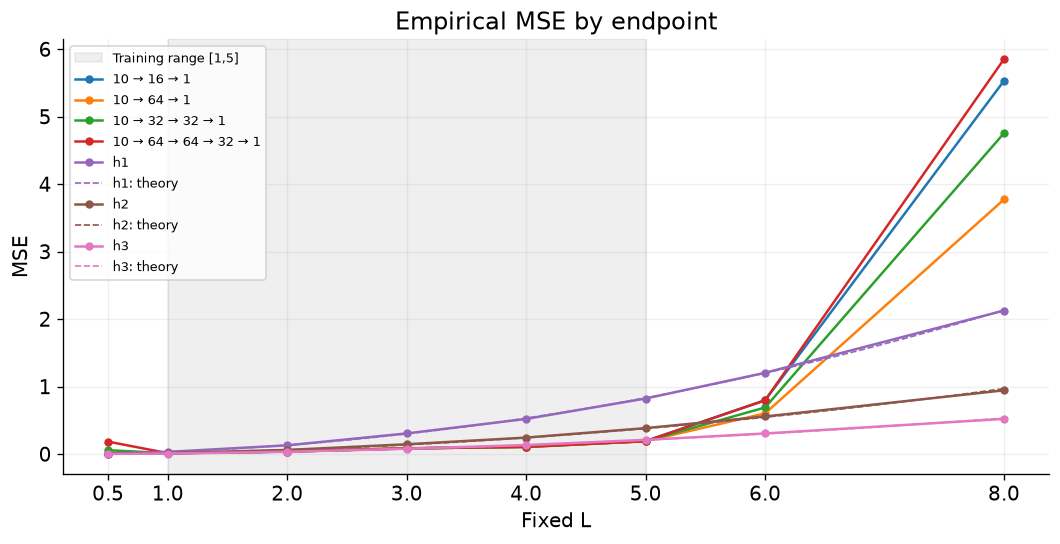

In [36]:
# Theoretical fixed-L risks from Part I, Task 1(b).
L_grid: FloatArray = np.linspace(L_VALUES.min(), L_VALUES.max(), 200)
theory_fixed: dict[str, FloatArray] = {'h1': L_grid ** 2 / (3 * N),
                                       'h2': 2 * L_grid ** 2 / ((N + 1) * (N + 2)),
                                       'h3': L_grid ** 2 / (N * (N + 2))}
fig, ax = plt.subplots(figsize=(9, 4.7))
ax.axvspan(1, 5, color='grey', alpha=0.12, label='Training range [1,5]')
for name in comparison.index:
    data = fixed_results[fixed_results.Model == name]
    line, = ax.plot(data.L, data.MSE, 'o-', label=name, markersize=4)
    if name in theory_fixed:
        ax.plot(L_grid, theory_fixed[name], '--', color=line.get_color(),
                linewidth=1, label=f'{name}: theory')
ax.set(xlabel='Fixed L', ylabel='MSE', xticks=L_VALUES,
       title='Empirical MSE by endpoint')
ax.legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()